# Load Relevant Libraries

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '6' #for my Windows computer
import pandas as pd
import numpy as np
from sklearn import preprocessing
from sklearn.metrics import pairwise
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.metrics import silhouette_score, silhouette_samples
from dmba import classificationSummary, gainsChart, liftChart
from dmba.metric import AIC_score
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
import matplotlib.pylab as plt
from sklearn.metrics import roc_curve
from sklearn.metrics import auc
import seaborn as sns
from pandas.plotting import parallel_coordinates
%matplotlib inline

# Read in the data

In [2]:
IBM = pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv')

# Observe shape of the data

In [3]:
IBM.shape

(1470, 35)

# Observe list of variables

In [4]:
IBM.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='object')

# Check for missing values

In [5]:
IBM.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

# Drop columns that do not provide value

EmployeeCount, Over18, and StandardHours do not vary between employees and have been removed.  The EmployeeNumber is just the observation number and does not add any data to be considered.  MonthlyRate and DailyRate behave as noise relative to the more important variable, MonthlyIncome.

In [6]:
IBM_Edit = IBM.drop(columns=['DailyRate','EmployeeCount','Over18','StandardHours', 'EmployeeNumber','HourlyRate','MonthlyRate'])

# Rechecking the shape of the data

In [7]:
IBM_Edit.shape

(1470, 28)

# Exloring the data's information and data types

In [8]:
IBM_Edit.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 28 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   Department                1470 non-null   object
 4   DistanceFromHome          1470 non-null   int64 
 5   Education                 1470 non-null   int64 
 6   EducationField            1470 non-null   object
 7   EnvironmentSatisfaction   1470 non-null   int64 
 8   Gender                    1470 non-null   object
 9   JobInvolvement            1470 non-null   int64 
 10  JobLevel                  1470 non-null   int64 
 11  JobRole                   1470 non-null   object
 12  JobSatisfaction           1470 non-null   int64 
 13  MaritalStatus             1470 non-null   object
 14  MonthlyIncome           

# Exploring how many people stayed -vs- how many left

Many more employees stayed with the company than the number of those who left the company.

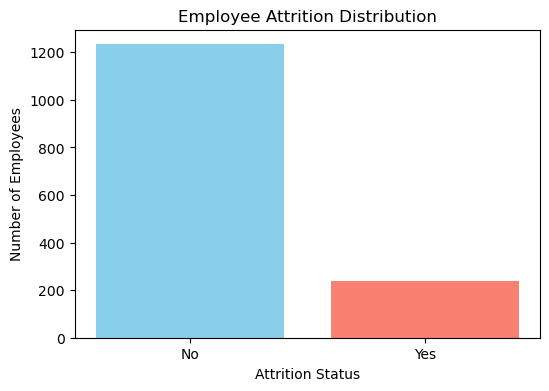

In [9]:
#creating a simple bar chart of 'yes' and 'no' with regard to attrition

attrition_counts = IBM_Edit["Attrition"].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(attrition_counts.index, attrition_counts.values, color=["skyblue", "salmon"])
plt.xlabel("Attrition Status")
plt.ylabel("Number of Employees")
plt.title("Employee Attrition Distribution")
plt.show()

# Exploring Attrition -vs- OverTime

Although slightly more employees with overtime left the company, the vast majority of employees stayed on the job.  

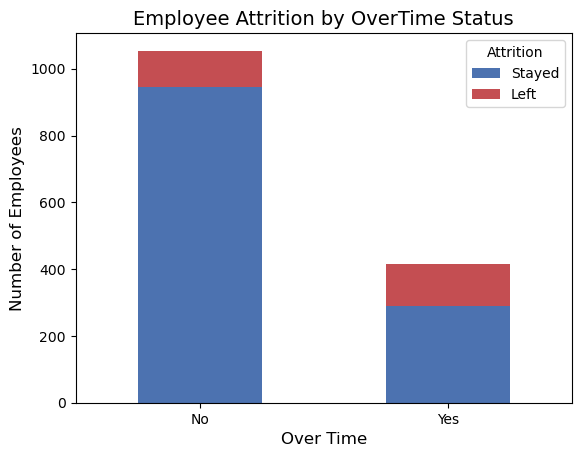

In [10]:
#creating a stacked bar chart looking at attrition 'yes' and 'no' against overtime 'yes' and 'no'

stack = pd.crosstab(IBM_Edit['OverTime'], IBM_Edit['Attrition'])

stack.plot(kind='bar', stacked=True, color=['#4C72B0', '#C44E52'], ax=plt.gca())
plt.title('Employee Attrition by OverTime Status', fontsize=14)
plt.xlabel('Over Time', fontsize=12)
plt.ylabel('Number of Employees', fontsize=12)
plt.legend(title='Attrition', labels=['Stayed', 'Left'])
plt.xticks(rotation=0)
plt.show()

# Checking for inconsistent data and spelling errors.

Data appears to be clean.

In [11]:
#check to see if there are any duplicates or spelling errors in the data also counting the number of each response.

cat_cols = IBM_Edit.select_dtypes(include=['object']).columns

for col in cat_cols:
    print(f"--- {col} ---")
    print(IBM_Edit[col].value_counts())
    print("\n")

--- Attrition ---
Attrition
No     1233
Yes     237
Name: count, dtype: int64


--- BusinessTravel ---
BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64


--- Department ---
Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64


--- EducationField ---
EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64


--- Gender ---
Gender
Male      882
Female    588
Name: count, dtype: int64


--- JobRole ---
JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype:

# Searching for outliers in the data. 

Outliers found in monthly income, performance rating, stock option level, total working years, years at company, years in current role, years since last promotion, and years with current manager.  These outliers will not be deleted.  They are being retained to assess attrition at all levels of employment.  

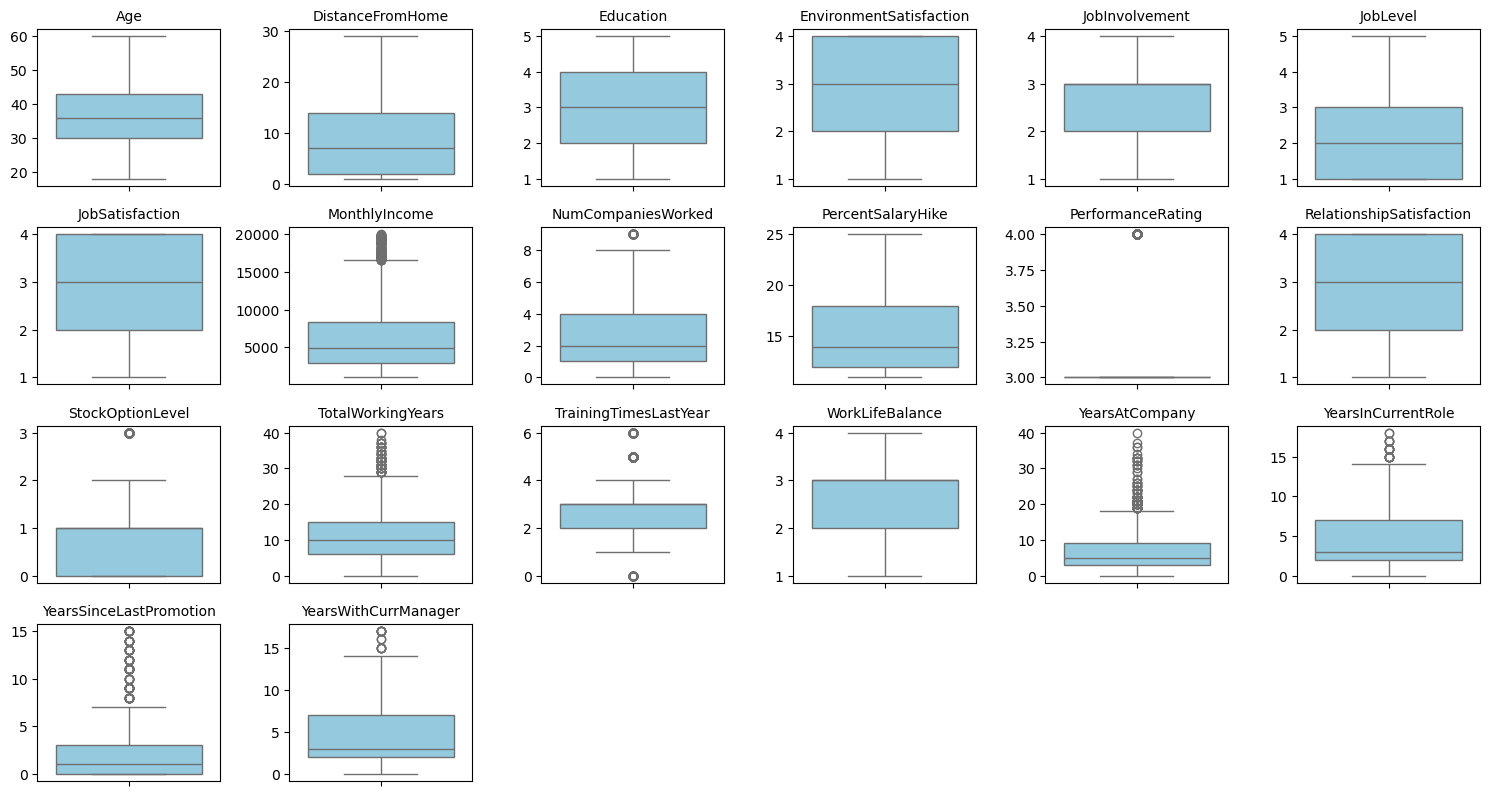

In [12]:
#creating box plots to look for outliers in the data.

num_cols = IBM_Edit.select_dtypes(exclude=['object']).columns

plt.figure(figsize=(15, 10))

for i, col in enumerate(num_cols, 1):
    plt.subplot(5, 6, i)
    sns.boxplot(y=IBM_Edit[col], color='skyblue')
    plt.title(col, fontsize=10)
    plt.ylabel('')

plt.tight_layout()
plt.show()

# Exploring the Categorical variables

Observing which variables are categorical and how many unique classes of each variable there are.

In [13]:
#pulling the categorical values to observe them.

IBM_Edit_Cat = IBM_Edit.select_dtypes(include = 'object').copy()
IBM_Edit_Cat

,Attrition,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus,OverTime
0,Yes,Travel_Rarely,Sales,Life Sciences,Female,Sales Executive,Single,Yes
1,No,Travel_Frequently,Research & Development,Life Sciences,Male,Research Scientist,Married,No
2,Yes,Travel_Rarely,Research & Development,Other,Male,Laboratory Technician,Single,Yes
3,No,Travel_Frequently,Research & Development,Life Sciences,Female,Research Scientist,Married,Yes
4,No,Travel_Rarely,Research & Development,Medical,Male,Laboratory Technician,Married,No
...,...,...,...,...,...,...,...,...
1465,No,Travel_Frequently,Research & Development,Medical,Male,Laboratory Technician,Married,No
1466,No,Travel_Rarely,Research & Development,Medical,Male,Healthcare Representative,Married,No
1467,No,Travel_Rarely,Research & Development,Life Sciences,Male,Manufacturing Director,Married,Yes
1468,No,Travel_Frequently,Sales,Medical,Male,Sales Executive,Married,No


In [14]:
#Finding the unique values under each variable type

IBM_Edit_Cat['Attrition'].unique()

array(['Yes', 'No'], dtype=object)

In [15]:
IBM_Edit_Cat['BusinessTravel'].unique()

array(['Travel_Rarely', 'Travel_Frequently', 'Non-Travel'], dtype=object)

In [16]:
IBM_Edit_Cat['Department'].unique()

array(['Sales', 'Research & Development', 'Human Resources'], dtype=object)

In [17]:
IBM_Edit_Cat['EducationField'].unique()

array(['Life Sciences', 'Other', 'Medical', 'Marketing',
       'Technical Degree', 'Human Resources'], dtype=object)

In [18]:
IBM_Edit_Cat['Gender'].unique()

array(['Female', 'Male'], dtype=object)

In [19]:
IBM_Edit_Cat['JobRole'].unique()

array(['Sales Executive', 'Research Scientist', 'Laboratory Technician',
       'Manufacturing Director', 'Healthcare Representative', 'Manager',
       'Sales Representative', 'Research Director', 'Human Resources'],
      dtype=object)

In [20]:
IBM_Edit_Cat['MaritalStatus'].unique()

array(['Single', 'Married', 'Divorced'], dtype=object)

In [21]:
IBM_Edit_Cat['OverTime'].unique()

array(['Yes', 'No'], dtype=object)

# Testing for Multicollinearity

Finding the Variance Inflation Factors, to test multicollinearity between variables.  This shows that normalization will have to take place when performing additional data analysis.  

In [22]:
#creating a dataframe of the numeric values to test for multicollinearity and checking for variance inflation factors 

numeric = ['Age', 'DistanceFromHome', 'JobLevel', 'MonthlyIncome','TotalWorkingYears', 'YearsAtCompany',
           'YearsInCurrentRole','PercentSalaryHike','TrainingTimesLastYear','YearsSinceLastPromotion', 'YearsWithCurrManager',
          'NumCompaniesWorked']
X=IBM_Edit[numeric].dropna()
X['constant'] = 1
vif_data = pd.DataFrame()
vif_data["Feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print(vif_data[vif_data["Feature"] != "constant"].sort_values(by="VIF", ascending=False))


                    Feature        VIF
2                  JobLevel  11.140064
3             MonthlyIncome  10.767455
4         TotalWorkingYears   4.737363
5            YearsAtCompany   4.548558
10     YearsWithCurrManager   2.750609
6        YearsInCurrentRole   2.675690
0                       Age   1.989592
9   YearsSinceLastPromotion   1.667292
11       NumCompaniesWorked   1.242912
1          DistanceFromHome   1.009640
8     TrainingTimesLastYear   1.007405
7         PercentSalaryHike   1.006715


# Producing a Correlation Matrix on numeric DataFrame

In [23]:
#Making a correlation matrix to further look for multicollinearity 

matrix=IBM_Edit[numeric].corr()
print(matrix)

                              Age  DistanceFromHome  JobLevel  MonthlyIncome  \
Age                      1.000000         -0.001686  0.509604       0.497855   
DistanceFromHome        -0.001686          1.000000  0.005303      -0.017014   
JobLevel                 0.509604          0.005303  1.000000       0.950300   
MonthlyIncome            0.497855         -0.017014  0.950300       1.000000   
TotalWorkingYears        0.680381          0.004628  0.782208       0.772893   
YearsAtCompany           0.311309          0.009508  0.534739       0.514285   
YearsInCurrentRole       0.212901          0.018845  0.389447       0.363818   
PercentSalaryHike        0.003634          0.040235 -0.034730      -0.027269   
TrainingTimesLastYear   -0.019621         -0.036942 -0.018191      -0.021736   
YearsSinceLastPromotion  0.216513          0.010029  0.353885       0.344978   
YearsWithCurrManager     0.202089          0.014406  0.375281       0.344079   
NumCompaniesWorked       0.299635       

Dropping TotalWorkingYears since it is highly correlated with MothlyIncome.  Keeping MothlyIncome.  Dropping YearsInCurrentRole since it is highly correlated with YearsAtCompany.  Keeping YearsAtCompany.  Dropping YearsWithCurrManager since it is also highly correlated with YearsAtCompany.  HourlyRate is also being dropped to avoid noise in the dataset.
 

In [24]:
#dropping variables that were highly correlated with other variables

IBM_Edit2=IBM_Edit.drop(columns=['TotalWorkingYears', 'YearsWithCurrManager', 'YearsInCurrentRole'])

# Get Dummies for Categorical Variables

Getting dummies for categorical variables to perform cluster analysis.

In [25]:
#Getting dummies for variables and specifying 'yes' as 1 and 'no' as 0

IBM_all = IBM_Edit.copy() 
IBM_all['Attrition'] = IBM_all['Attrition'].map({'Yes': 1, 'No': 0})
IBM_Encoded = pd.get_dummies(IBM_all, drop_first=True).astype(int)

#printing all the column names
print("Columns:")
for col in IBM_Encoded.columns:
    print(col)

Columns:
Age
Attrition
DistanceFromHome
Education
EnvironmentSatisfaction
JobInvolvement
JobLevel
JobSatisfaction
MonthlyIncome
NumCompaniesWorked
PercentSalaryHike
PerformanceRating
RelationshipSatisfaction
StockOptionLevel
TotalWorkingYears
TrainingTimesLastYear
WorkLifeBalance
YearsAtCompany
YearsInCurrentRole
YearsSinceLastPromotion
YearsWithCurrManager
BusinessTravel_Travel_Frequently
BusinessTravel_Travel_Rarely
Department_Research & Development
Department_Sales
EducationField_Life Sciences
EducationField_Marketing
EducationField_Medical
EducationField_Other
EducationField_Technical Degree
Gender_Male
JobRole_Human Resources
JobRole_Laboratory Technician
JobRole_Manager
JobRole_Manufacturing Director
JobRole_Research Director
JobRole_Research Scientist
JobRole_Sales Executive
JobRole_Sales Representative
MaritalStatus_Married
MaritalStatus_Single
OverTime_Yes


In [26]:
#observing the encoded data

IBM_Encoded

,Age,Attrition,DistanceFromHome,Education,EnvironmentSatisfaction,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,NumCompaniesWorked,...,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single,OverTime_Yes
0,41,1,1,2,2,3,2,4,5993,8,...,0,0,0,0,0,1,0,0,1,1
1,49,0,8,1,3,2,2,2,5130,1,...,0,0,0,0,1,0,0,1,0,0
2,37,1,2,2,4,2,1,3,2090,6,...,1,0,0,0,0,0,0,0,1,1
3,33,0,3,4,4,3,1,3,2909,1,...,0,0,0,0,1,0,0,1,0,1
4,27,0,2,1,1,3,1,2,3468,9,...,1,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,0,23,2,3,4,2,4,2571,4,...,1,0,0,0,0,0,0,1,0,0
1466,39,0,6,1,4,2,3,1,9991,4,...,0,0,0,0,0,0,0,1,0,0
1467,27,0,4,3,2,4,2,2,6142,1,...,0,0,1,0,0,0,0,1,0,1
1468,49,0,2,3,4,2,2,2,5390,2,...,0,0,0,0,0,1,0,1,0,0


# More Exploration of the Data

A heatmap of the data with a smaller range of -.3 to .3 to better show relationships.  This heatmap echoes the relationships observed in previous analyses.  

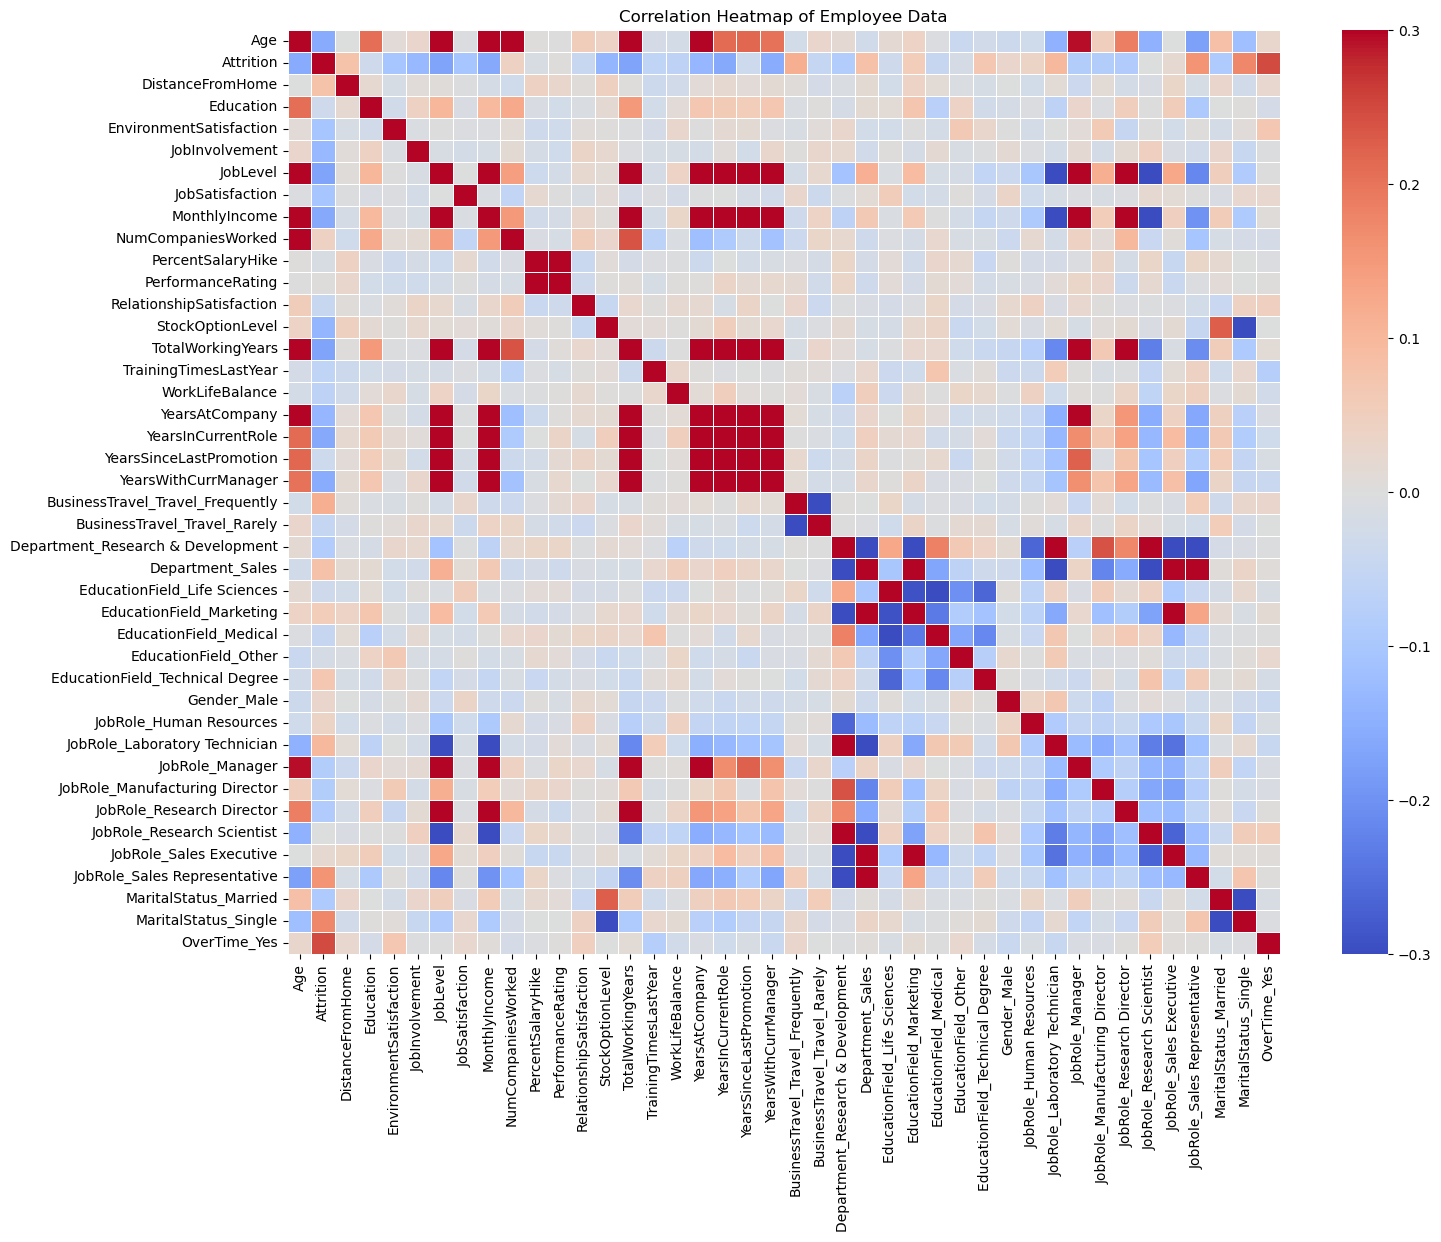

In [27]:
#creating a heatmap to look at more correlation between variables.

plt.figure(figsize=(16, 12))
correlation_matrix = IBM_Encoded.corr()
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', linewidths=0.5, vmin=-0.3, vmax=0.3) #using a smaller scale to better observe relationships
plt.title('Correlation Heatmap of Employee Data')
plt.show()

# Looking at variables most and least correlated to Attrition

In [28]:
#Creating a correlation matrix looking at the correlation between attrition and all the other variables.

attrition_corr = correlation_matrix['Attrition'].sort_values(ascending=False)
print("--- Top Drivers FOR Leaving (Positive Correlation) ---")
print(attrition_corr.iloc[1:11]) 
print("\n--- Top Drivers FOR Staying (Negative Correlation) ---")
print(attrition_corr.tail(10))

--- Top Drivers FOR Leaving (Positive Correlation) ---
OverTime_Yes                        0.246118
MaritalStatus_Single                0.175419
JobRole_Sales Representative        0.157234
BusinessTravel_Travel_Frequently    0.115143
JobRole_Laboratory Technician       0.098290
Department_Sales                    0.080855
DistanceFromHome                    0.077924
EducationField_Technical Degree     0.069355
EducationField_Marketing            0.055781
NumCompaniesWorked                  0.043494
Name: Attrition, dtype: float64

--- Top Drivers FOR Staying (Negative Correlation) ---
JobSatisfaction        -0.103481
JobInvolvement         -0.130016
YearsAtCompany         -0.134392
StockOptionLevel       -0.137145
YearsWithCurrManager   -0.156199
Age                    -0.159205
MonthlyIncome          -0.159840
YearsInCurrentRole     -0.160545
JobLevel               -0.169105
TotalWorkingYears      -0.171063
Name: Attrition, dtype: float64


# Normalizing the Data for Clustering

Normalizing the data so that large variables like MonthlyIncome don't carry more weight than smaller variables like DistanceFromHome.  

In [29]:
#creating a dataframe without the attrition column, converting the variables to floats, and normalizing the data

IBM_cluster = IBM_Encoded.drop('Attrition', axis=1)
IBM_float = IBM_cluster.apply(lambda x: x.astype('float64'))
IBM_norm = IBM_float.apply(preprocessing.scale, axis=0)

# Making an Elbow Chart

The Elbow Chart is being used to assess the number of clusters to be used for further analysis.  The cluster number of 4 will be used.

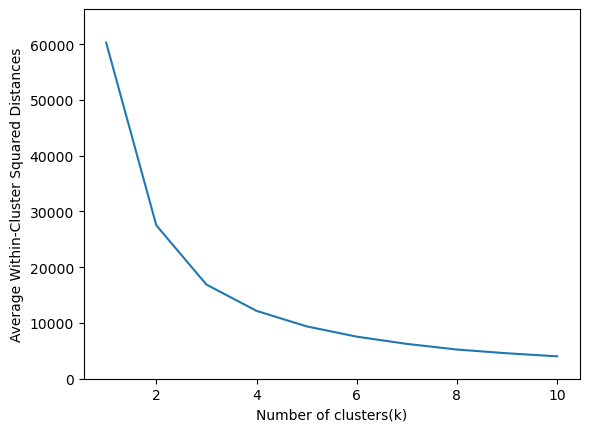

In [30]:
#creating an empty list (inertia), using loop to test cluster sizes 1-11, running the algorithm 10 times, and plotting the data

inertia = []
for n_clusters in range(1,11):
    kmeans = KMeans(n_clusters=n_clusters, n_init=10, random_state=0).fit(IBM_norm)
    inertia.append(kmeans.inertia_/n_clusters)

inertias = pd.DataFrame({'n_clusters':  range(1,11), 'inertia':inertia})
ax = inertias.plot(x='n_clusters', y='inertia')
plt.xlabel('Number of clusters(k)')
plt.ylabel('Average Within-Cluster Squared Distances')
plt.ylim((0, 1.1 * inertias.inertia.max()))
ax.legend().set_visible(False)
plt.show()

# Building the K-means Model

Using a K-means model to discover groups and patterns within the data.  

In [31]:
#training the KMeans model with 4 clusters

kmeans = KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=0).fit(IBM_norm)
memb = pd.Series(kmeans.labels_, index=IBM_norm.index) #map rows to clusters
for key, item in memb.groupby(memb):
    print(key, ':',','.join(item.index.astype(str))) #group and print the results

0 : 0,27,39,43,46,48,52,54,56,70,76,82,89,91,92,94,96,97,107,115,117,121,124,131,132,133,137,138,144,151,154,158,167,168,174,178,205,210,212,216,218,219,223,227,228,241,254,261,265,273,277,281,282,293,295,297,303,306,319,320,321,327,328,331,335,338,339,343,349,354,355,358,359,366,368,374,376,378,380,384,387,393,397,402,403,423,427,433,442,444,446,447,450,452,458,460,461,462,467,469,475,482,484,486,499,502,504,507,517,518,520,521,525,527,528,532,533,536,545,548,563,566,567,569,573,576,583,591,607,608,612,619,621,622,624,625,628,634,638,641,646,651,652,659,672,679,684,685,693,695,698,702,703,704,705,706,708,719,747,748,751,757,760,768,771,775,791,795,801,802,805,807,811,820,821,829,834,836,839,844,849,865,866,870,872,879,884,885,888,897,908,917,926,935,946,947,950,951,960,963,964,968,974,975,981,984,986,987,990,991,993,996,1011,1013,1019,1025,1026,1030,1031,1038,1041,1047,1048,1049,1051,1057,1058,1063,1067,1070,1084,1094,1103,1105,1106,1109,1119,1120,1121,1124,1132,1143,1144,1162,1167,11

# Making it Readable

The K-means model reveals four clusters: 3-Entry Level with the highest PercentSalaryHike, TrainingTimesLastYear, and WorkLifeBalance, 2-Intermediate Level with highest EnvironmentSatisfaction and JobInvolvement, 1-Senior Level with the highest Age, Education, JobLevel, MonthlyIncome, NumCompaniesWorked, PerformanceRating, RelationshipSatisfaction, TotalWorkingYears, YearsAtCompany, YearsInCurrentRole, YearsSinceLastPromotion, and YearsWithCurrentManager, and 0-Mid Level with highest DistanceFromHome, and JobSatisfaction.

In [32]:
#adding cluster labels to the dataset in a column named 'Cluster_Profile', calculate means of each variable in each cluster

IBM_Edit['Cluster_Profile'] = kmeans.labels_
all_numeric_summary = IBM_Edit.groupby('Cluster_Profile').mean(numeric_only=True)
print(all_numeric_summary.T.round(1)) #transpose and print

Cluster_Profile                0        1       2       3
Age                         36.6     45.9    35.0    32.3
DistanceFromHome             9.6      8.9     9.2     8.5
Education                    3.0      3.1     2.9     2.7
EnvironmentSatisfaction      2.7      2.7     2.8     2.7
JobInvolvement               2.7      2.7     2.8     2.7
JobLevel                     2.3      3.9     1.5     1.2
JobSatisfaction              2.8      2.7     2.7     2.7
MonthlyIncome             6778.6  15114.5  4191.7  3192.1
NumCompaniesWorked           2.7      3.4     2.6     2.1
PercentSalaryHike           14.9     15.1    15.3    15.4
PerformanceRating            3.1      3.2     3.2     3.1
RelationshipSatisfaction     2.7      2.8     2.7     2.7
StockOptionLevel             0.8      0.8     0.8     0.7
TotalWorkingYears           10.7     23.5     8.5     5.9
TrainingTimesLastYear        2.8      2.8     2.8     2.9
WorkLifeBalance              2.8      2.7     2.7     2.9
YearsAtCompany

# How do these Clusters relate to Attrition?

Comparing each cluster to Attrition. Entry Career Level individuals leave more than any other group.

In [33]:
#creating a new dataframe called attrition_by_cluster to see the percentage of 'yes' and 'no' with regard to attrition

attrition_by_cluster = pd.crosstab(IBM_Edit['Cluster_Profile'], IBM_Edit['Attrition'], normalize='index') * 100 #making the numbers a percentage
print("--- Percentage of Attrition by Cluster ---")
print(attrition_by_cluster.round(1))

--- Percentage of Attrition by Cluster ---
Attrition          No   Yes
Cluster_Profile            
0                82.7  17.3
1                94.4   5.6
2                83.9  16.1
3                67.2  32.8


# Evaluating the K-Means model with Silhouette Scores

The positive overall silhouette score indicates career levels have been identified, but the borders between them are blurred.

In [34]:
#Calculating the Overall Score and every employee
overall_score = silhouette_score(IBM_norm, kmeans.labels_)
print(f"Overall Silhouette Score: {overall_score:.4f}")
individual_scores = silhouette_samples(IBM_norm, kmeans.labels_)

#Grouping scores to measure tightness of clusters
score_df = pd.DataFrame({'Cluster': kmeans.labels_, 'Silhouette_Score': individual_scores})
cluster_avg_scores = score_df.groupby('Cluster').mean()
print("\n--- Average Silhouette Score per Cluster ---")
print(cluster_avg_scores.round(3))

Overall Silhouette Score: 0.1118

--- Average Silhouette Score per Cluster ---
         Silhouette_Score
Cluster                  
0                   0.162
1                   0.053
2                   0.116
3                   0.077


# Running a Logistic Regression

Using the normalized dataframe with dummies, preparing to run a logistic regression

In [35]:
#Convert Yes and No to 1 and 0
IBM_Edit['Attrition'] = IBM_Edit['Attrition'].map({'Yes': 1, 'No': 0})

#Partition Data; dropping 'JobLevel' because of its high multicollinearity with 'MonthlyIncome'
X = IBM_norm.drop(columns=['JobLevel'])
y = IBM_Edit['Attrition'] #Using the non-normalized 'Attrition' outcome variable that is a simple binary outcome
train_X, valid_X, train_y, valid_y = train_test_split(X, y, test_size=0.4, random_state=1)

In [36]:
#Fitting the model and generating coefficients
#fitting a logistic regression (setting penalty to l2 and C=1e42 to avoid regularization)

logit_reg = LogisticRegression(penalty='l2', C=1e42, solver='liblinear')
logit_reg.fit(train_X, train_y)

print('intercept', logit_reg.intercept_[0])
print('AIC', AIC_score(valid_y, logit_reg.predict(valid_X), df = len(train_X.columns)+1))

#Printing the head and tail of the list of coefficients

coefficients = pd.DataFrame({'Variable': X.columns, 'Coefficient': logit_reg.coef_[0]})
coefficients = coefficients.sort_values(by='Coefficient', ascending=False)

print("\nTOP DRIVERS OF ATTRITION (Highest Positive Coefficients):")
print(coefficients.head(5).to_string(index=False))

print("\nTOP DRIVERS OF RETENTION (Highest Negative Coefficients):")
print(coefficients.tail(5).to_string(index=False))

intercept -2.7723090521484384
AIC 622.3124798813649

TOP DRIVERS OF ATTRITION (Highest Positive Coefficients):
                         Variable  Coefficient
                 Department_Sales     4.060476
Department_Research & Development     3.977309
          JobRole_Human Resources     1.602095
                     OverTime_Yes     0.882923
 BusinessTravel_Travel_Frequently     0.858677

TOP DRIVERS OF RETENTION (Highest Negative Coefficients):
                    Variable  Coefficient
    EducationField_Marketing    -0.570331
        YearsWithCurrManager    -0.637010
        EducationField_Other    -0.747064
EducationField_Life Sciences    -1.222942
      EducationField_Medical    -1.252695


# Scoring the validation data

Looking at the head and the tail

In [37]:
#Looking at the head and tail of the prediction model

logit_reg_pred = logit_reg.predict(valid_X)
logit_reg_proba = logit_reg.predict_proba(valid_X)
logit_result = pd.DataFrame({'actual' : valid_y,
                            'p(0)': [p[0] for p in logit_reg_proba],
                            'p(1)': [p[1] for p in logit_reg_proba],
                            'predicted': logit_reg_pred})
print(logit_result.head(10))
print(logit_result.tail(10))

      actual      p(0)      p(1)  predicted
1291       1  0.972898  0.027102          0
1153       1  0.201897  0.798103          1
720        1  0.392778  0.607222          1
763        0  0.519979  0.480021          0
976        0  0.818574  0.181426          0
724        0  0.993447  0.006553          0
314        0  0.737125  0.262875          0
258        0  0.969991  0.030009          0
442        0  0.936838  0.063162          0
1393       0  0.981539  0.018461          0
      actual      p(0)      p(1)  predicted
430        0  0.554577  0.445423          0
1432       0  0.988446  0.011554          0
1006       1  0.290177  0.709823          1
1297       1  0.902412  0.097588          0
1073       0  0.939111  0.060889          0
1186       1  0.831132  0.168868          0
207        0  0.717113  0.282887          0
237        0  0.333840  0.666160          1
860        1  0.770539  0.229461          0
345        0  0.968130  0.031870          0


# Calculating Standard Odds

Using the Logistic Odds to calculate the Standard Odds

In [38]:
#Creating a dataframe of the log Odds and Variables
full_results = pd.DataFrame({
    'Variable': X.columns, 
    'Log_Odds': logit_reg.coef_[0]
})

#Calculating Standard Odds, sorting the table and printing
full_results['Standard_Odds'] = np.exp(full_results['Log_Odds'])
full_results = full_results.sort_values(by='Standard_Odds', ascending=False)

print("--- FULL MODEL BUSINESS MULTIPLIERS ---")
print(full_results.to_string(index=False))

--- FULL MODEL BUSINESS MULTIPLIERS ---
                         Variable  Log_Odds  Standard_Odds
                 Department_Sales  4.060476      58.001910
Department_Research & Development  3.977309      53.373209
          JobRole_Human Resources  1.602095       4.963419
                     OverTime_Yes  0.882923       2.417957
 BusinessTravel_Travel_Frequently  0.858677       2.360036
                   YearsAtCompany  0.771660       2.163354
    JobRole_Laboratory Technician  0.699872       2.013495
     BusinessTravel_Travel_Rarely  0.692782       1.999270
          YearsSinceLastPromotion  0.609627       1.839745
             MaritalStatus_Single  0.562103       1.754359
     JobRole_Sales Representative  0.430017       1.537283
                 DistanceFromHome  0.400238       1.492180
               NumCompaniesWorked  0.336316       1.399781
          JobRole_Sales Executive  0.250207       1.284291
       JobRole_Research Scientist  0.209672       1.233274
            Mari

# Calculating Probability

In [39]:
#Calculating the probability % using standard odds

full_results['Probability'] = full_results['Standard_Odds'] / (1 + full_results['Standard_Odds'])
full_results['Probability_Percentage'] = (full_results['Probability'] * 100).round(2).astype(str) + '%'

#Printing the variable, odds, and probability %

print("--- BUSINESS SCORECARD ---")
print(full_results[['Variable', 'Standard_Odds', 'Probability_Percentage']].to_string(index=False))

--- BUSINESS SCORECARD ---
                         Variable  Standard_Odds Probability_Percentage
                 Department_Sales      58.001910                 98.31%
Department_Research & Development      53.373209                 98.16%
          JobRole_Human Resources       4.963419                 83.23%
                     OverTime_Yes       2.417957                 70.74%
 BusinessTravel_Travel_Frequently       2.360036                 70.24%
                   YearsAtCompany       2.163354                 68.39%
    JobRole_Laboratory Technician       2.013495                 66.82%
     BusinessTravel_Travel_Rarely       1.999270                 66.66%
          YearsSinceLastPromotion       1.839745                 64.79%
             MaritalStatus_Single       1.754359                 63.69%
     JobRole_Sales Representative       1.537283                 60.59%
                 DistanceFromHome       1.492180                 59.87%
               NumCompaniesWorked    

# Creating a Confusion Matrix

In [40]:
#training confusion matrix
classificationSummary(train_y, logit_reg.predict(train_X))

#validation confusion matrix
classificationSummary(valid_y, logit_reg.predict(valid_X))

Confusion Matrix (Accuracy 0.9014)

       Prediction
Actual   0   1
     0 728  19
     1  68  67
Confusion Matrix (Accuracy 0.8537)

       Prediction
Actual   0   1
     0 468  18
     1  68  34


# Calculating Precision, Recall, Specificity, and the ROC Curve

In [41]:
#Precision, Recall, Specificity, and F1 Score

tn, fp, fn, tp = confusion_matrix(valid_y, logit_reg_pred).ravel()
accuracy = accuracy_score(valid_y, logit_reg_pred)
precision = precision_score(valid_y, logit_reg_pred)
recall = recall_score(valid_y, logit_reg_pred)
specificity = tn / (tn + fp)
f1 = f1_score(valid_y, logit_reg_pred)

print("--- MODEL EVALUATION METRICS ---")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"F1 Score:  {f1:.4f}")

--- MODEL EVALUATION METRICS ---
Accuracy:  0.8537
Precision: 0.6538
Recall:    0.3333
Specificity: 0.9630
F1 Score:  0.4416


# ROC Curve and Calculate AUC (Receiver Operating Characteristic)

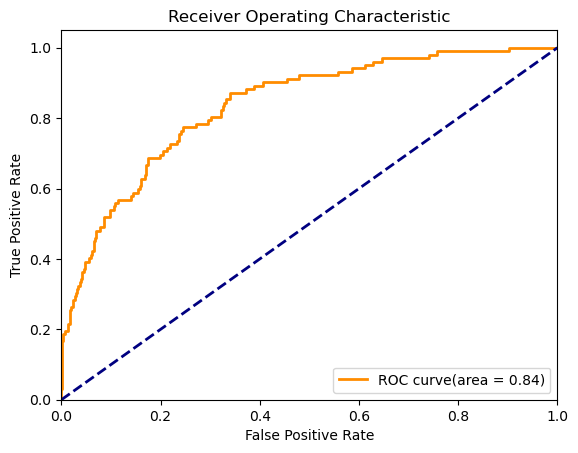

AUC: 0.8358145727426772


In [42]:
#Plotting ROC Curve and Calculating AUC (Receiver Operating Characteristic / Area Under the Curve)

fpr, tpr, _ = roc_curve(valid_y, logit_reg_proba[:, 1])
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve(area = {roc_auc:.2f})')
plt.plot([0,1], [0,1], color = 'navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc = "lower right")
plt.show()

print(f'AUC: {roc_auc}')

# Re-running the Logistic Regression on Optimized Data

An additional, more specific, Logistic Regression limiting the predictor variables to Age, Education, Monthly Income, Percent Salary Hike, Martial Status Married, Marital Status Single, Overtime Yes, Gender Male, Business Travel Travel Frequently, and Business Travel Travel Rarely.

In [43]:
#Keeping the top features

top_features = [
    'Age', 
    'Education', 
    'MonthlyIncome', 
    'PercentSalaryHike', 
    'MaritalStatus_Married', 
    'MaritalStatus_Single', 
    'OverTime_Yes',
    'Gender_Male',
    'BusinessTravel_Travel_Frequently',
    'BusinessTravel_Travel_Rarely'
]

X_reduced = IBM_norm[top_features]

In [44]:
#training the data/partitioning
train_X_red, valid_X_red, train_y_red, valid_y_red = train_test_split(X_reduced, y, test_size=0.4, random_state=1)

#fitting the model
logit_reg_reduced = LogisticRegression(penalty='l2', C=1e42, solver='liblinear')
logit_reg_reduced.fit(train_X_red, train_y_red)

print('intercept', logit_reg_reduced.intercept_[0])
print('AIC', AIC_score(valid_y_red, logit_reg_reduced.predict(valid_X_red), df = len(train_X_red.columns)+1))

#Printing the head and tail of the list of coefficients

coeff = pd.DataFrame({'Variable': X_reduced.columns, 'Coefficient': logit_reg_reduced.coef_[0]})
coeff = coeff.sort_values(by='Coefficient', ascending=False)

print("\nTOP DRIVERS OF ATTRITION (Highest Coefficients):")
print(coeff.head(5).to_string(index=False))

print("\nTOP DRIVERS OF RETENTION (Lowest Coefficients):")
print(coeff.tail(5).to_string(index=False))

intercept -2.0631511127361
AIC 645.0867415634411

TOP DRIVERS OF ATTRITION (Highest Coefficients):
                        Variable  Coefficient
                    OverTime_Yes     0.697003
BusinessTravel_Travel_Frequently     0.594825
            MaritalStatus_Single     0.528241
    BusinessTravel_Travel_Rarely     0.485424
           MaritalStatus_Married     0.168543

TOP DRIVERS OF RETENTION (Lowest Coefficients):
         Variable  Coefficient
      Gender_Male     0.122228
        Education     0.111878
PercentSalaryHike    -0.039023
              Age    -0.236964
    MonthlyIncome    -0.362523


# Scoring the validation data on optimized data

Taking a small sample 

In [45]:
logit_reg_reduced_pred = logit_reg_reduced.predict(valid_X_red)
logit_reg_reduced_proba = logit_reg_reduced.predict_proba(valid_X_red)
logit_result_reduced = pd.DataFrame({'actual' : valid_y_red,
                            'p(0)': [p[0] for p in logit_reg_reduced_proba],
                            'p(1)': [p[1] for p in logit_reg_reduced_proba],
                            'predicted': logit_reg_reduced_pred})
print(logit_result_reduced.head(10))
print(logit_result_reduced.tail(10))

      actual      p(0)      p(1)  predicted
1291       1  0.812477  0.187523          0
1153       1  0.311401  0.688599          1
720        1  0.665388  0.334612          0
763        0  0.684389  0.315611          0
976        0  0.879883  0.120117          0
724        0  0.945395  0.054605          0
314        0  0.888199  0.111801          0
258        0  0.929279  0.070721          0
442        0  0.949934  0.050066          0
1393       0  0.785329  0.214671          0
      actual      p(0)      p(1)  predicted
430        0  0.821255  0.178745          0
1432       0  0.871334  0.128666          0
1006       1  0.832452  0.167548          0
1297       1  0.666881  0.333119          0
1073       0  0.925816  0.074184          0
1186       1  0.386865  0.613135          1
207        0  0.799913  0.200087          0
237        0  0.927814  0.072186          0
860        1  0.431625  0.568375          1
345        0  0.919129  0.080871          0


# Calculating Standard Odds on Optimized Data

Using logistic odds to calculate standard odds

In [46]:
#Creating a dataframe of the log Odds and Variables
reduced_results = pd.DataFrame({
    'Variable': X_reduced.columns, 
    'Log_Odds': logit_reg_reduced.coef_[0]
})

#Calculating Standard Odds, sorting the table and printing
reduced_results['Standard_Odds'] = np.exp(reduced_results['Log_Odds'])
reduced_results = reduced_results.sort_values(by='Standard_Odds', ascending=False)

print("--- FULL MODEL BUSINESS MULTIPLIERS ---")
print(reduced_results.to_string(index=False))

--- FULL MODEL BUSINESS MULTIPLIERS ---
                        Variable  Log_Odds  Standard_Odds
                    OverTime_Yes  0.697003       2.007727
BusinessTravel_Travel_Frequently  0.594825       1.812714
            MaritalStatus_Single  0.528241       1.695946
    BusinessTravel_Travel_Rarely  0.485424       1.624864
           MaritalStatus_Married  0.168543       1.183579
                     Gender_Male  0.122228       1.130012
                       Education  0.111878       1.118376
               PercentSalaryHike -0.039023       0.961729
                             Age -0.236964       0.789020
                   MonthlyIncome -0.362523       0.695918


# Calculating Probability with Optimized Data

In [47]:
#Calculating the probability % using standard odds

reduced_results['Probability'] = reduced_results['Standard_Odds'] / (1 + reduced_results['Standard_Odds'])
reduced_results['Probability_Percentage'] = (reduced_results['Probability'] * 100).round(2).astype(str) + '%'

#Printing the variable, odds, and probability %

print("--- FINAL BUSINESS SCORECARD ---")
print(reduced_results[['Variable', 'Standard_Odds', 'Probability_Percentage']].to_string(index=False))

--- FINAL BUSINESS SCORECARD ---
                        Variable  Standard_Odds Probability_Percentage
                    OverTime_Yes       2.007727                 66.75%
BusinessTravel_Travel_Frequently       1.812714                 64.45%
            MaritalStatus_Single       1.695946                 62.91%
    BusinessTravel_Travel_Rarely       1.624864                  61.9%
           MaritalStatus_Married       1.183579                  54.2%
                     Gender_Male       1.130012                 53.05%
                       Education       1.118376                 52.79%
               PercentSalaryHike       0.961729                 49.02%
                             Age       0.789020                  44.1%
                   MonthlyIncome       0.695918                 41.03%


# Creating a Confusion Matrix with Optimized Data

In [48]:
#training confusion matrix
classificationSummary(train_y_red, logit_reg_reduced.predict(train_X_red))

#validation confusion matrix
classificationSummary(valid_y_red, logit_reg_reduced.predict(valid_X_red))

Confusion Matrix (Accuracy 0.8651)

       Prediction
Actual   0   1
     0 735  12
     1 107  28
Confusion Matrix (Accuracy 0.8316)

       Prediction
Actual   0   1
     0 476  10
     1  89  13


# Calculating Precision, Recall, Specificity, and the ROC Curve with optimized Data

In [49]:
#Precision, Recall, Specificity, and F1 Score

tn, fp, fn, tp = confusion_matrix(valid_y_red, logit_reg_reduced_pred).ravel()
accuracy_red = accuracy_score(valid_y_red, logit_reg_reduced_pred)
precision_red = precision_score(valid_y_red, logit_reg_reduced_pred)
recall_red = recall_score(valid_y_red, logit_reg_reduced_pred)
specificity_red = tn / (tn + fp)
f1_red = f1_score(valid_y_red, logit_reg_reduced_pred)

print("--- MODEL EVALUATION METRICS ---")
print(f"Accuracy:  {accuracy_red:.4f}")
print(f"Precision: {precision_red:.4f}")
print(f"Recall:    {recall_red:.4f}")
print(f"Specificity: {specificity_red:.4f}")
print(f"F1 Score:  {f1_red:.4f}")

--- MODEL EVALUATION METRICS ---
Accuracy:  0.8316
Precision: 0.5652
Recall:    0.1275
Specificity: 0.9794
F1 Score:  0.2080


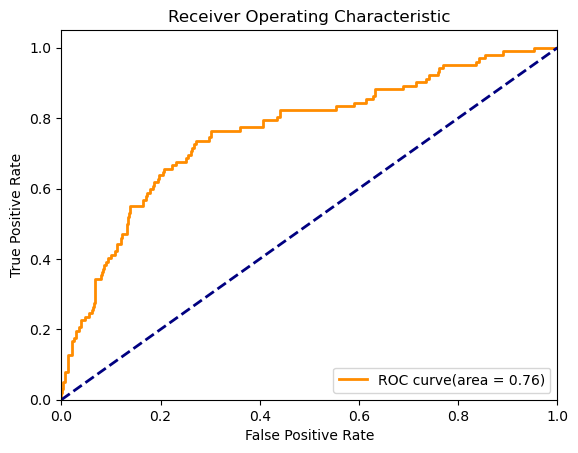

AUC: 0.7630718954248366


In [50]:
#Plotting ROC Curve and Calculating AUC (Receiver Operating Characteristic / Area Under the Curve)

fpr, tpr, _ = roc_curve(valid_y_red, logit_reg_reduced_proba[:, 1])
roc_auc_red = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve(area = {roc_auc_red:.2f})')
plt.plot([0,1], [0,1], color = 'navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc = "lower right")
plt.show()

print(f'AUC: {roc_auc_red}')

# Bringing it all together

Looking at the distribution of the top three triggers for attrition:  OverTime_Yes, BusinessTravel_Travel_Frequently, and MartialStatus_Single amoung the four clusters.

In [51]:
#Adding 'Cluster' to the dataframe

IBM_Encoded['Cluster'] = score_df['Cluster']

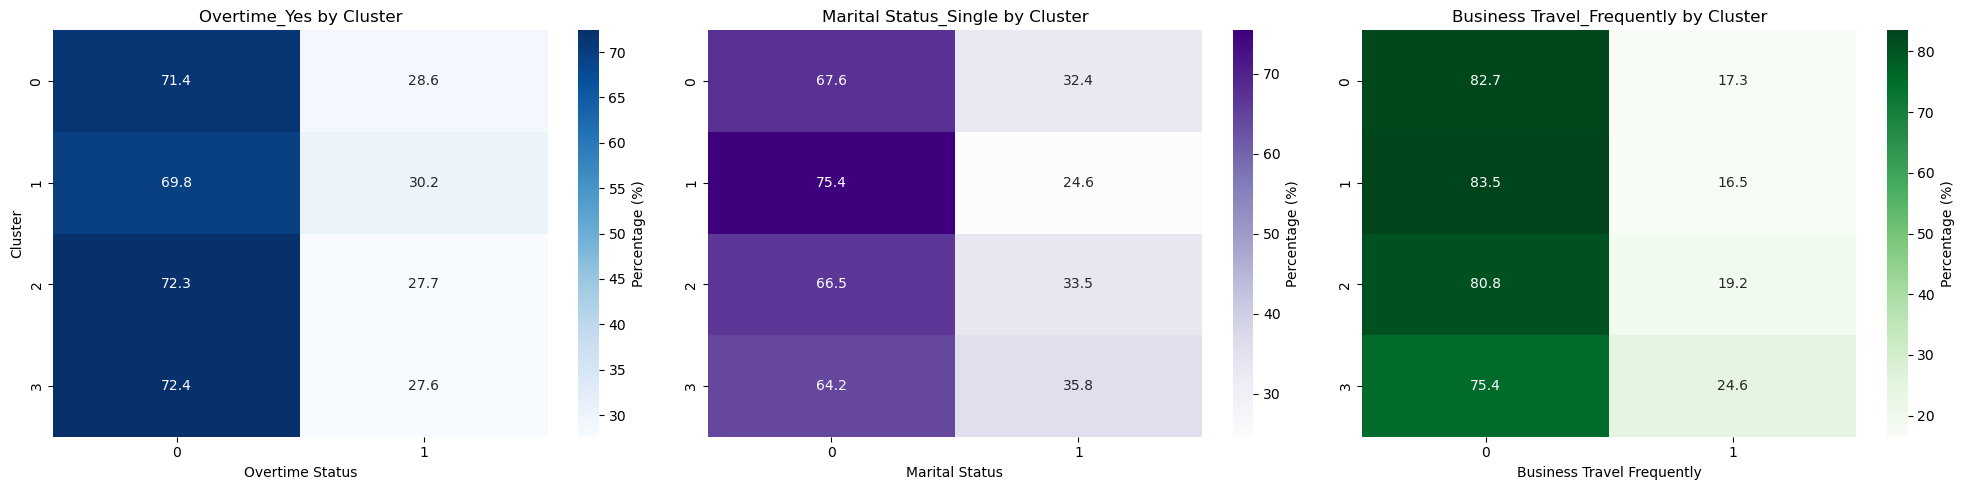

In [52]:
# Creating three subplots, one for each variable
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Creating the overtime vs clusters heatmap
cl_overtime = pd.crosstab(IBM_Encoded['Cluster'], IBM_Encoded['OverTime_Yes'], normalize='index') * 100
sns.heatmap(cl_overtime, annot=True, fmt=".1f", cmap="Blues", 
            cbar_kws={'label': 'Percentage (%)'}, ax=axes[0])
axes[0].set_title("Overtime_Yes by Cluster")
axes[0].set_ylabel("Cluster")
axes[0].set_xlabel("Overtime Status")

# Creating the marital status vs clusters heatmap
cl_marital = pd.crosstab(IBM_Encoded['Cluster'], IBM_Encoded['MaritalStatus_Single'], normalize='index') * 100
sns.heatmap(cl_marital, annot=True, fmt=".1f", cmap="Purples", 
            cbar_kws={'label': 'Percentage (%)'}, ax=axes[1])
axes[1].set_title("Marital Status_Single by Cluster")
axes[1].set_ylabel("") # Hiding ylabel here to keep it clean
axes[1].set_xlabel("Marital Status")

# Creating the business travel vs clusters heatmap
cl_travel = pd.crosstab(IBM_Encoded['Cluster'], IBM_Encoded['BusinessTravel_Travel_Frequently'], normalize='index') * 100
sns.heatmap(cl_travel, annot=True, fmt=".1f", cmap="Greens", 
            cbar_kws={'label': 'Percentage (%)'}, ax=axes[2])
axes[2].set_title("Business Travel_Frequently by Cluster")
axes[2].set_ylabel("") # Hiding ylabel
axes[2].set_xlabel("Business Travel Frequently")

plt.tight_layout() 
plt.show()